Task 4 Sentiment Analysis

Reviews Dataset Download

In [2]:
import pandas as pd

data = {
    "Review": [
        "This product is amazing and excellent",
        "I really love this product",
        "Very good quality and fast delivery",
        "Worst product ever",
        "I am very disappointed",
        "The quality is poor",
        "The product is okay",
        "It is an average product",
        "The product arrived yesterday",
        "Excellent quality and wonderful experience",
        "I hate this product",
        "Not bad, but could be better"
    ]
}

df = pd.DataFrame(data)

df.head()

,Review
0,This product is amazing and excellent
1,I really love this product
2,Very good quality and fast delivery
3,Worst product ever
4,I am very disappointed


Sentiment Column

In [3]:
df["Sentiment"] = [
    "Positive",
    "Positive",
    "Positive",
    "Negative",
    "Negative",
    "Negative",
    "Neutral",
    "Neutral",
    "Neutral",
    "Positive",
    "Negative",
    "Neutral"
]

df.head(12)

,Review,Sentiment
0,This product is amazing and excellent,Positive
1,I really love this product,Positive
2,Very good quality and fast delivery,Positive
3,Worst product ever,Negative
4,I am very disappointed,Negative
5,The quality is poor,Negative
6,The product is okay,Neutral
7,It is an average product,Neutral
8,The product arrived yesterday,Neutral
9,Excellent quality and wonderful experience,Positive


Text Preprocessing

In [4]:
# Convert text into lowercase
df["Cleaned_Review"] = df["Review"].str.lower()

# Remove extra spaces
df["Cleaned_Review"] = df["Cleaned_Review"].str.strip()

df[["Review", "Cleaned_Review"]].head(12)

,Review,Cleaned_Review
0,This product is amazing and excellent,this product is amazing and excellent
1,I really love this product,i really love this product
2,Very good quality and fast delivery,very good quality and fast delivery
3,Worst product ever,worst product ever
4,I am very disappointed,i am very disappointed
5,The quality is poor,the quality is poor
6,The product is okay,the product is okay
7,It is an average product,it is an average product
8,The product arrived yesterday,the product arrived yesterday
9,Excellent quality and wonderful experience,excellent quality and wonderful experience


VADER Sentiment Analyzer

In [5]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

print("VADER Sentiment Analyzer Loaded Successfully!")

VADER Sentiment Analyzer Loaded Successfully!


Perform Sentiment Analysis

In [6]:
def get_sentiment(text):
    scores = analyzer.polarity_scores(text)

    if scores["compound"] >= 0.05:
        return "Positive"
    elif scores["compound"] <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df["Predicted_Sentiment"] = df["Cleaned_Review"].apply(get_sentiment)

df[["Review", "Sentiment", "Predicted_Sentiment"]]

,Review,Sentiment,Predicted_Sentiment
0,This product is amazing and excellent,Positive,Positive
1,I really love this product,Positive,Positive
2,Very good quality and fast delivery,Positive,Positive
3,Worst product ever,Negative,Negative
4,I am very disappointed,Negative,Negative
5,The quality is poor,Negative,Negative
6,The product is okay,Neutral,Positive
7,It is an average product,Neutral,Neutral
8,The product arrived yesterday,Neutral,Neutral
9,Excellent quality and wonderful experience,Positive,Positive


Sentiment Score

In [7]:
df["Sentiment_Scores"] = df["Cleaned_Review"].apply(
    lambda text: analyzer.polarity_scores(text)
)

df["Compound_Score"] = df["Sentiment_Scores"].apply(
    lambda score: score["compound"]
)

df[["Review", "Compound_Score", "Predicted_Sentiment"]]

,Review,Compound_Score,Predicted_Sentiment
0,This product is amazing and excellent,0.8176,Positive
1,I really love this product,0.6697,Positive
2,Very good quality and fast delivery,0.4927,Positive
3,Worst product ever,-0.6249,Negative
4,I am very disappointed,-0.5256,Negative
5,The quality is poor,-0.4767,Negative
6,The product is okay,0.2263,Positive
7,It is an average product,0.0000,Neutral
8,The product arrived yesterday,0.0000,Neutral
9,Excellent quality and wonderful experience,0.8126,Positive


Sentiment Distribution Chart

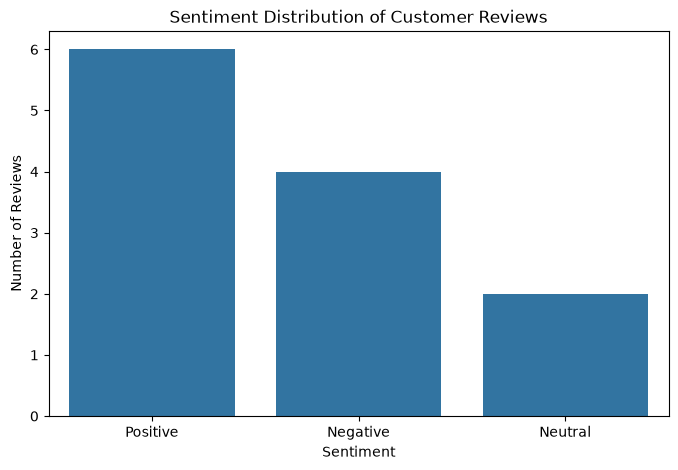

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sentiment_counts = df["Predicted_Sentiment"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Sentiment Distribution of Customer Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

Sentiment Analysis Pie Chart

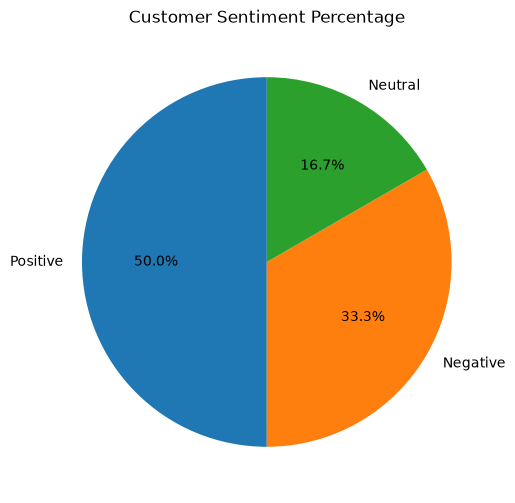

In [9]:
sentiment_counts = df["Predicted_Sentiment"].value_counts()

plt.figure(figsize=(8, 6))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Sentiment Percentage")

plt.show()

Word Cloud

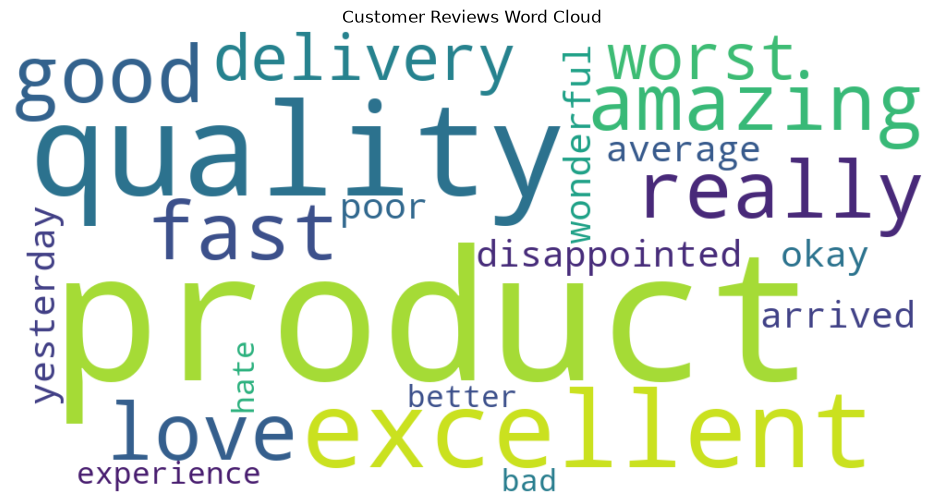

In [10]:
from wordcloud import WordCloud

text = " ".join(df["Cleaned_Review"])

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(text)

plt.figure(figsize=(12, 6))

plt.imshow(wordcloud, interpolation="bilinear")

plt.axis("off")

plt.title("Customer Reviews Word Cloud")

plt.show()

Sentiment Analysis Insights

In [11]:
print("SENTIMENT ANALYSIS - KEY INSIGHTS")

print("\nTotal Reviews:", len(df))

print("\nSentiment Counts:")
print(df["Predicted_Sentiment"].value_counts())

print("\nPositive Reviews:",
      (df["Predicted_Sentiment"] == "Positive").sum())

print("\nNegative Reviews:",
      (df["Predicted_Sentiment"] == "Negative").sum())

print("\nNeutral Reviews:",
      (df["Predicted_Sentiment"] == "Neutral").sum())

print("\nAverage Compound Score:",
      round(df["Compound_Score"].mean(), 3))

SENTIMENT ANALYSIS - KEY INSIGHTS

Total Reviews: 12

Sentiment Counts:
Predicted_Sentiment
Positive    6
Negative    4
Neutral     2
Name: count, dtype: int64

Positive Reviews: 6

Negative Reviews: 4

Neutral Reviews: 2

Average Compound Score: 0.126


Sentiment Analysis Dashboard

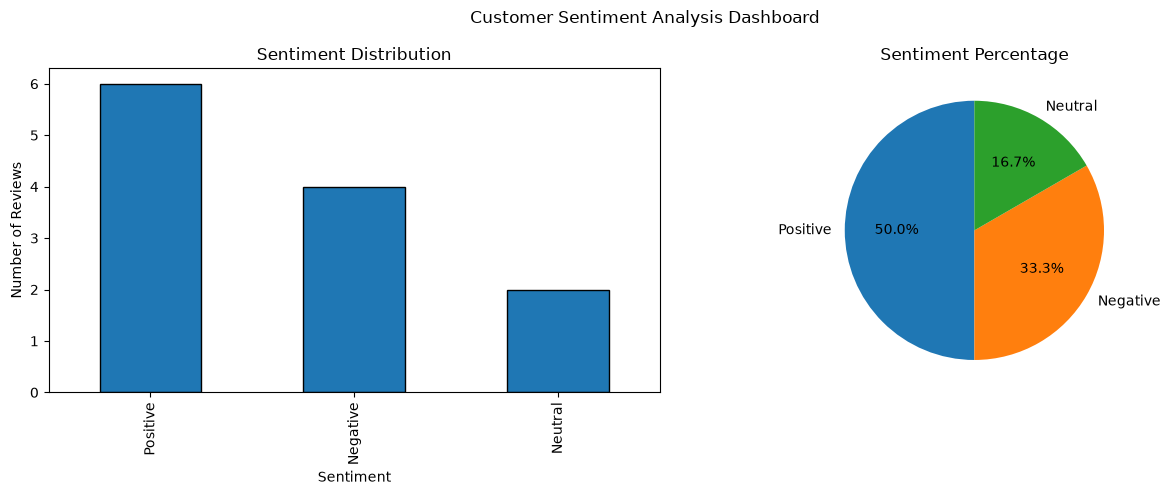

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Bar Chart
sentiment_counts.plot(
    kind="bar",
    ax=axes[0],
    edgecolor="black"
)

axes[0].set_title("Sentiment Distribution")
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Number of Reviews")

# Pie Chart
axes[1].pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

axes[1].set_title("Sentiment Percentage")

plt.suptitle("Customer Sentiment Analysis Dashboard")
plt.tight_layout()
plt.show()

Dashboard Image Save

In [13]:
import os

os.makedirs("visualizations", exist_ok=True)

fig.savefig(
    "visualizations/Sentiment_Dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

print("Dashboard saved successfully!")

Dashboard saved successfully!


In [14]:
df.to_csv("CodeAlpha_Reviews_Dataset.csv", index=False)
print("Dataset saved successfully!")

Dataset saved successfully!
